# Homework 3: Noise and Linear Light
## Name: Jon Knapp
### Date: October 27, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

## Part 1: Captures
### Problem 1: Capture at least ten pairs of flat fields spanning the range from nearly black to nearly saturated, two frames at each level with nothing moved or changed between them.
 _Deliverables: A contact sheet showing one frame from each pair, and a list giving the exposure time and ISO of every capture._

In [1]:
# If rawpy isn't installed:  %pip install rawpy
from fractions import Fraction
from pathlib import Path
import tifffile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
from matplotlib.patches import Rectangle

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"
PATCH = 128   # side of the central measurement patch, in green-plane pixels

In [3]:
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None

def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {Path(path).name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so the two frames of a pair group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {Path(path).name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    return f"{float(f):.3g} s" if f >= 1 else f"1/{1 / f:.4g} s"


def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files

In [4]:
def green_plane(path):
    """Return (green plane in DN, black level of that plane, white level).
    Takes the first green site of the 2x2 Bayer tile, so it is one green
    channel, not a mix of G1 and G2."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)   # copy before the file closes
        pattern = r.raw_pattern
        desc = r.color_desc.decode()
        gi, gj = next((i, j) for i in range(2) for j in range(2)
                      if desc[pattern[i, j]] == "G")
        black = float(r.black_level_per_channel[pattern[gi, gj]])
        white = float(r.white_level)
    return raw[gi::2, gj::2], black, white


def center_patch(plane, n=PATCH):
    h, w = plane.shape
    top, left = (h - n) // 2, (w - n) // 2
    return plane[top:top + n, left:left + n]

In [5]:
def capture_table(folder):
    rows = []
    for f in dng_files(folder):
        et = exposure_of(f)
        g, black, white = green_plane(f)
        m = center_patch(g).mean()
        rows.append({
            "file": f.name,
            "exposure": fmt_exposure(et),
            "exposure_s": float(et),
            "ISO": iso_of(f),
            "black_DN": black,
            "white_DN": white,
            "center_mean_DN": m,
            "pct_saturation": 100 * (m - black) / (white - black),
        })
    df = pd.DataFrame(rows).sort_values(["exposure_s", "file"]).reset_index(drop=True)
    df.insert(0, "pair", df.groupby("exposure_s", sort=True).ngroup() + 1)
    return df


white_df = capture_table(WHITE_DIR)
white_df.round({"exposure_s": 5, "center_mean_DN": 1, "pct_saturation": 1})

,pair,file,exposure,exposure_s,ISO,black_DN,white_DN,center_mean_DN,pct_saturation
0,1,IMG_0638.DNG,1/30 s,0.03333,50,528.0,4095.0,4079.4,99.6
1,1,IMG_0639.DNG,1/30 s,0.03333,50,528.0,4095.0,4079.5,99.6
2,2,IMG_0636.DNG,1/15 s,0.06667,50,528.0,4095.0,4079.4,99.6
3,2,IMG_0637.DNG,1/15 s,0.06667,50,528.0,4095.0,4079.4,99.6
4,3,IMG_0634.DNG,1/8 s,0.12500,50,528.0,4095.0,4079.4,99.6
5,3,IMG_0635.DNG,1/8 s,0.12500,50,528.0,4095.0,4079.4,99.6
6,4,IMG_0632.DNG,1/4 s,0.25000,50,528.0,4095.0,4079.4,99.6
7,4,IMG_0633.DNG,1/4 s,0.25000,50,528.0,4095.0,4079.4,99.6
8,5,IMG_0630.DNG,1/3 s,0.33333,50,528.0,4095.0,4080.1,99.6
9,5,IMG_0631.DNG,1/3 s,0.33333,50,528.0,4095.0,4080.1,99.6


In [6]:
counts = white_df.groupby("pair").size()
bad_pairs = counts[counts != 2]
short = white_df[white_df.exposure_s < 1 / 50]

print(f"{len(white_df)} flat-field frames, {white_df.pair.nunique()} exposure levels")
print(f"ISO value(s): {sorted(int(i) for i in white_df.ISO.unique())}")
print(f"Central-patch level spans {white_df.pct_saturation.min():.1f}% "
      f"to {white_df.pct_saturation.max():.1f}% of saturation")
if white_df.pair.nunique() < 10:
    print("! Fewer than 10 levels; the assignment asks for at least ten pairs.")
if len(bad_pairs):
    print("! Levels without exactly 2 frames:", dict(bad_pairs))
if len(short):
    print("! Exposures shorter than 1/50 s (screen flicker risk):",
          ", ".join(short.file))

14 flat-field frames, 7 exposure levels
ISO value(s): [50]
Central-patch level spans 99.6% to 99.6% of saturation
! Fewer than 10 levels; the assignment asks for at least ten pairs.


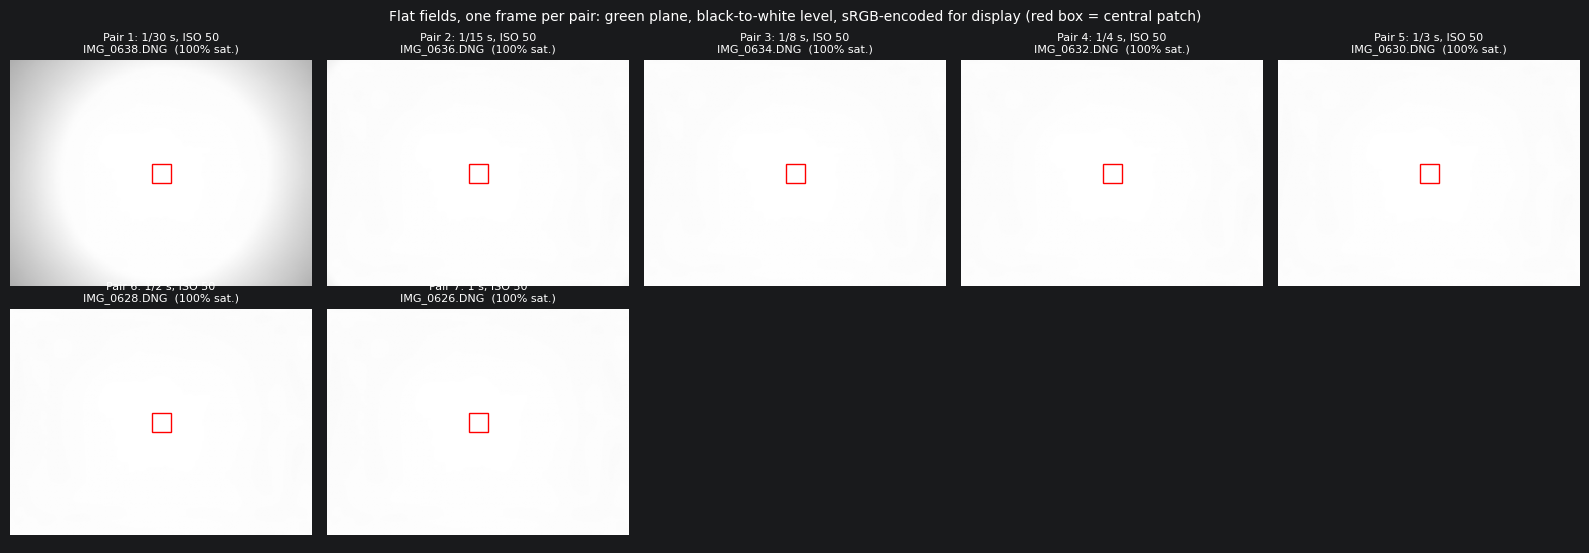

In [9]:
def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


def thumbnail(plane, black, white, factor=8):
    """Normalize to [0, 1] of the raw range, block-average in linear light, then encode."""
    x = (plane - black) / (white - black)
    h, w = (s // factor * factor for s in x.shape)
    x = x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))
    return srgb_encode(x)


FACTOR = 8
reps = white_df.groupby("pair").first().reset_index()
ncols = 5
nrows = int(np.ceil(len(reps) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), squeeze=False)

for ax, row in zip(axes.flat, reps.itertuples()):
    g, black, white = green_plane(WHITE_DIR / row.file)
    t = thumbnail(g, black, white, FACTOR)
    ax.imshow(t, cmap="gray", vmin=0, vmax=1)
    # outline the central patch used in Part 2
    s = PATCH / FACTOR
    ax.add_patch(Rectangle(((t.shape[1] - s) / 2, (t.shape[0] - s) / 2), s, s,
                           fill=False, edgecolor="red", linewidth=1))
    ax.set_title(f"Pair {row.pair}: {row.exposure}, ISO {row.ISO}\n"
                 f"{row.file}  ({row.pct_saturation:.0f}% sat.)", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(reps):]:
    ax.axis("off")

fig.suptitle("Flat fields, one frame per pair: green plane, black-to-white level, "
             "sRGB-encoded for display (red box = central patch)", fontsize=10)
fig.tight_layout()
fig.savefig("hw3_item1_contact_sheet.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
white_df[["pair", "file", "exposure", "exposure_s", "ISO"]].style.hide(axis="index")

pair,file,exposure,exposure_s,ISO
1,IMG_0638.DNG,1/30 s,0.033333,50
1,IMG_0639.DNG,1/30 s,0.033333,50
2,IMG_0636.DNG,1/15 s,0.066667,50
2,IMG_0637.DNG,1/15 s,0.066667,50
3,IMG_0634.DNG,1/8 s,0.125000,50
3,IMG_0635.DNG,1/8 s,0.125000,50
4,IMG_0632.DNG,1/4 s,0.250000,50
4,IMG_0633.DNG,1/4 s,0.250000,50
5,IMG_0630.DNG,1/3 s,0.333333,50
5,IMG_0631.DNG,1/3 s,0.333333,50


### Problem 2: Confirm from the metadata that the entire series came from one camera at one ISO, using the lens_id helper from the Project 1 page together with the ISO field.
_Deliverable: The assertion passing, or an account of which captures differ and what you did about it._

In [11]:
"""
Homework 3 (Noise and Linear Light), Item 2:
Confirm from the metadata that every capture came from one camera at one ISO.

Run from the folder that contains "Homework 3 Image Captures":
    python hw3_item2_metadata_check.py

It prints a table of every DNG (lens, focal length, frame size, ISO, exposure),
groups the flat fields by exposure time so you can see the pairs, and asserts
that each series has exactly one camera and one ISO. The table doubles as the
"exposure time and ISO of every capture" list for item 1.
"""

from collections import defaultdict
from fractions import Fraction
from pathlib import Path

import tifffile

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"


# --- lens_id helper, as given on the Project 1 page --------------------------
def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


# --- ISO and exposure time ----------------------------------------------------
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {path.name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so pairs group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {path.name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    if f >= 1:
        return f"{float(f):.3g} s"
    return f"1/{1 / f:.4g} s"


# --- per-series check ---------------------------------------------------------
def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files


def describe_series(name, files):
    rows = []
    for f in files:
        rows.append((f, lens_id(f), iso_of(f), exposure_of(f)))

    print(f"\n=== {name}: {len(files)} files ===")
    print(f"{'file':<28} {'ISO':>5} {'exposure':>12}  lens")
    for f, lid, iso, et in rows:
        print(f"{f.name:<28} {iso:>5} {fmt_exposure(et):>12}  {lid[0]}, "
              f"{lid[1]} mm, {lid[2]} mm equiv, {lid[3][0]}x{lid[3][1]}")

    lens_ids = {lid for _, lid, _, _ in rows}
    isos = {iso for _, _, iso, _ in rows}

    # If something differs, say which files, before the assert fires.
    for label, values, idx in (("camera", lens_ids, 1), ("ISO", isos, 2)):
        if len(values) > 1:
            print(f"\n  ! More than one {label} in {name}:")
            groups = defaultdict(list)
            for r in rows:
                groups[r[idx]].append(r[0].name)
            for v, names in groups.items():
                print(f"    {v}: {', '.join(names)}")

    return rows, lens_ids, isos


def print_pairs(rows):
    """Group flat fields by exposure time; each level should hold 2 frames."""
    by_exp = defaultdict(list)
    for f, _, _, et in rows:
        by_exp[et].append(f.name)
    print(f"\n  Flat-field levels ({len(by_exp)} exposure times):")
    for et in sorted(by_exp):
        names = by_exp[et]
        flag = "" if len(names) == 2 else f"   <-- {len(names)} frames, expected 2"
        print(f"    {fmt_exposure(et):>12}: {', '.join(names)}{flag}")
    short = [et for et in by_exp if et < Fraction(1, 50)]
    if short:
        print("  ! Exposures shorter than 1/50 s (screen flicker risk): "
              + ", ".join(fmt_exposure(e) for e in sorted(short)))


if __name__ == "__main__":
    white_rows, white_lens, white_iso = describe_series("White Frames",
                                                        dng_files(WHITE_DIR))
    print_pairs(white_rows)
    dark_rows, dark_lens, dark_iso = describe_series("Dark Frames",
                                                     dng_files(DARK_DIR))
    print_pairs(dark_rows)

    all_lens = white_lens | dark_lens
    all_iso = white_iso | dark_iso
    print("\nCamera(s):", all_lens)
    print("ISO(s):   ", all_iso)

    assert len(white_lens) == 1, f"more than one camera in white frames: {white_lens}"
    assert len(white_iso) == 1, f"more than one ISO in white frames: {white_iso}"
    assert len(dark_lens) == 1, f"more than one camera in dark frames: {dark_lens}"
    assert len(dark_iso) == 1, f"more than one ISO in dark frames: {dark_iso}"
    assert all_lens == white_lens, f"dark and white frames from different cameras: {all_lens}"
    assert all_iso == white_iso, f"dark and white frames at different ISOs: {all_iso}"
    print("\nPASS: all captures from one camera at one ISO.")


=== White Frames: 14 files ===
file                           ISO     exposure  lens
IMG_0626.DNG                    50          1 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0627.DNG                    50          1 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0628.DNG                    50        1/2 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0629.DNG                    50        1/2 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0630.DNG                    50        1/3 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0631.DNG                    50        1/3 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0632.DNG                    50        1/4 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0633.DNG      

### Problem 3: Capture five dark frames with the lens covered at each of four exposure times, spanning the longest range your app allows, and compare their level against the black level recorded in the file.
_Deliverable: The black level per channel from the file, the mean of your shortest dark frames in digital numbers, and one sentence on whether the two agree._

In [16]:
def bayer_channels(path):
    """Black level from the file and measured statistics for each of the four Bayer sites."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)
        pattern = r.raw_pattern.copy()
        desc = r.color_desc.decode()
        blacks = [float(b) for b in r.black_level_per_channel]
    out, g_count = [], 0
    for i in range(2):
        for j in range(2):
            c = pattern[i, j]
            name = desc[c]
            if name == "G":                      # label the two green sites G1 and G2
                g_count += 1
                name = f"G{g_count}"
            site = raw[i::2, j::2]
            out.append({"channel": name,
                        "black_DN": blacks[c],
                        "mean_DN": site.mean(),
                        "std_DN": site.std()})
    return out

In [17]:
rows = []
for f in dng_files(DARK_DIR):
    et = exposure_of(f)
    for ch in bayer_channels(f):
        rows.append({"file": f.name, "exposure": fmt_exposure(et),
                     "exposure_s": float(et), "ISO": iso_of(f), **ch})
dark_ch = pd.DataFrame(rows)

per_level = (dark_ch.groupby("exposure_s")
             .agg(exposure=("exposure", "first"), frames=("file", "nunique")))
print(f"{dark_ch.file.nunique()} dark frames at {len(per_level)} exposure times, "
      f"spanning {per_level.exposure.iloc[0]} to {per_level.exposure.iloc[-1]}")
for _, r in per_level.iterrows():
    flag = "" if r.frames >= 5 else f"   <-- {r.frames} frames, need 5"
    print(f"  {r.exposure:>10}: {r.frames} frames{flag}")
if len(per_level) < 4:
    print("! Fewer than 4 exposure times.")

14 dark frames at 7 exposure times, spanning 1/30 s to 1 s
      1/30 s: 2 frames   <-- 2 frames, need 5
      1/15 s: 2 frames   <-- 2 frames, need 5
       1/8 s: 2 frames   <-- 2 frames, need 5
       1/4 s: 2 frames   <-- 2 frames, need 5
       1/3 s: 2 frames   <-- 2 frames, need 5
       1/2 s: 2 frames   <-- 2 frames, need 5
         1 s: 2 frames   <-- 2 frames, need 5


In [18]:
spread = dark_ch.groupby("channel").black_DN.agg(["min", "max"])
if (spread["min"] != spread["max"]).any():
    print("! The recorded black level differs between files:")
    print(spread)

black_per_channel = dark_ch.groupby("channel", sort=False).black_DN.first().to_frame()
black_per_channel

,black_DN
channel,
B,528.0
G1,528.0
G2,528.0
R,528.0


In [28]:
t_min = dark_ch.exposure_s.min()
shortest = dark_ch[dark_ch.exposure_s == t_min]
n_frames = shortest.file.nunique()
print(f"Shortest exposure: {fmt_exposure(Fraction(t_min).limit_denominator(1_000_000))}, "
      f"{n_frames} frames: {', '.join(shortest.file.unique())}")

summary = shortest.groupby("channel", sort=False).agg(
    black_DN=("black_DN", "first"),
    mean_DN=("mean_DN", "mean"),
    frame_to_frame_sd_DN=("mean_DN", "std"),   # spread of the per-frame means
    pixel_std_DN=("std_DN", "mean"),           # noise within one frame
)
summary["mean_minus_black_DN"] = summary.mean_DN - summary.black_DN
summary["std_error_DN"] = summary.frame_to_frame_sd_DN / np.sqrt(n_frames)

all_mean = shortest.mean_DN.mean()
all_black = shortest.black_DN.mean()
print(f"All channels: mean {all_mean:.2f} DN vs. black level {all_black:.2f} DN "
      f"(difference {all_mean - all_black:+.2f} DN)")

display(summary.round(3))

diff = all_mean - all_black
print(f"Shortest dark frames: {all_mean:.2f} DN vs. recorded black level {all_black:.0f} DN, "
      f"difference {diff:+.2f} DN ({100 * diff / (4095 - all_black):+.3f}% of the raw range)")

Shortest exposure: 1/30 s, 2 frames: IMG_0609.DNG, IMG_0610.DNG
All channels: mean 527.43 DN vs. black level 528.00 DN (difference -0.57 DN)


,black_DN,mean_DN,frame_to_frame_sd_DN,pixel_std_DN,mean_minus_black_DN,std_error_DN
channel,,,,,,
B,528.0,527.364,0.003,1.720,-0.636,0.002
G1,528.0,527.477,0.007,1.725,-0.523,0.005
G2,528.0,527.478,0.008,1.729,-0.522,0.005
R,528.0,527.390,0.009,1.862,-0.610,0.006


Shortest dark frames: 527.43 DN vs. recorded black level 528 DN, difference -0.57 DN (-0.016% of the raw range)


The shortest dark frames average 527.43 DN against a recorded black level of 528 DN in every channel, so the two agree to within 0.6 DN (0.02% of the 3567 DN range), with the measured pedestal sitting slightly below the value in the file.

## Part 2: The Photon Transfer Curve

### Problem 4: Before fitting any of your own data, run your photon transfer code on the simulated sensor in the lecture 5 demo notebook, which reports the true gain and read noise it used to generate the frames.
_Deliverable: Your recovered gain and read noise beside the true values, as percentage errors._

In [25]:
def pair_stats(a, b, black, n=PATCH):
    """Mean above black and single-frame variance from one flat-field pair.
    Mean: average of the two frame means, black subtracted.
    Variance: half the variance of the difference, so fixed pattern cancels."""
    a = center_patch(np.asarray(a, dtype=np.float64), n)
    b = center_patch(np.asarray(b, dtype=np.float64), n)
    mean = 0.5 * (a.mean() + b.mean()) - black
    var = np.var(a - b, ddof=1) / 2
    return mean, var, a.size


def fit_ptc(mean, var, full_scale, frac=0.70, weighted=True):
    """Fit Var = K * mean + K^2 sigma_r^2 to the points below `frac` of full scale.

    full_scale is white level minus black level, in DN. With weighted=True each
    point is weighted by 1/variance, since the scatter of a variance estimate is
    proportional to the variance itself; this keeps the bright points from
    dominating the intercept. Returns gain and read noise with 1-sigma
    uncertainties from the fit covariance."""
    mean = np.asarray(mean, dtype=np.float64)
    var = np.asarray(var, dtype=np.float64)
    used = (mean > 0) & (mean < frac * full_scale)
    if used.sum() < 4:
        raise ValueError(f"Only {used.sum()} points below {frac:.0%} of saturation; need at least 4.")

    w = 1 / var[used] if weighted else None
    (K, c), cov = np.polyfit(mean[used], var[used], 1, w=w, cov=True)
    sig_K, sig_c = np.sqrt(np.diag(cov))

    if c > 0:
        read = np.sqrt(c) / K
        J = np.array([-np.sqrt(c) / K**2, 1 / (2 * K * np.sqrt(c))])  # d(read)/d(K, c)
        sig_read = float(np.sqrt(J @ cov @ J))
    else:
        read, sig_read = np.nan, np.nan          # intercept fit below zero

    return {"K": K, "sig_K": sig_K, "intercept": c, "sig_intercept": sig_c,
            "read": read, "sig_read": sig_read, "used": used, "cov": cov}

In [26]:
import sys

PSU_DIR = None   # set to the folder containing psu_imaging.py if it isn't found automatically

search = [Path(PSU_DIR)] if PSU_DIR else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for parent in search:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        print(f"psu_imaging.py found in {parent}")
        break
else:
    raise FileNotFoundError("psu_imaging.py not found. Set PSU_DIR to the folder that contains it.")

import psu_imaging as psu

# Ground truth, exactly as the demo defines it
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL   # DN per electron
TRUE_READ = psu.READ_NOISE                                      # electrons RMS
SIM_PRNU = 0.012

def sim_flat_pair(electrons, level_index):
    """Same as the demo's flat_pair: two independent 128x128 frames at one level."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=SIM_PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=SIM_PRNU)
    return a.astype(float), b.astype(float)

sim_levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
sim_pairs = [sim_flat_pair(e, i) for i, e in enumerate(sim_levels)]
print(f"{len(sim_pairs)} simulated pairs, black {psu.BLACK_LEVEL} DN, white {psu.WHITE_LEVEL} DN")

psu_imaging.py found in C:\Users\jknap\PycharmProjects\EE513\Project 1
22 simulated pairs, black 256 DN, white 4095 DN


In [27]:
sim_stats = np.array([pair_stats(a, b, psu.BLACK_LEVEL)[:2] for a, b in sim_pairs])
sim_fit = fit_ptc(sim_stats[:, 0], sim_stats[:, 1],
                  full_scale=psu.WHITE_LEVEL - psu.BLACK_LEVEL)

pct = lambda est, true: 100 * (est - true) / true
validation = pd.DataFrame({
    "quantity": ["conversion gain K (DN/e-)", "read noise (e-)"],
    "true": [TRUE_K, TRUE_READ],
    "recovered": [sim_fit["K"], sim_fit["read"]],
    "fit uncertainty (1 sigma)": [sim_fit["sig_K"], sim_fit["sig_read"]],
    "error (%)": [pct(sim_fit["K"], TRUE_K), pct(sim_fit["read"], TRUE_READ)],
})
validation["error / uncertainty"] = ((validation.recovered - validation.true)
                                     / validation["fit uncertainty (1 sigma)"])

print(f"{sim_fit['used'].sum()} of {len(sim_pairs)} pairs below 70% of saturation used in the fit")
validation.round(4).style.hide(axis="index")

21 of 22 pairs below 70% of saturation used in the fit


quantity,true,recovered,fit uncertainty (1 sigma),error (%),error / uncertainty
conversion gain K (DN/e-),0.426600,0.423300,0.001100,-0.762400,-3.028000
read noise (e-),2.800000,2.944300,0.017900,5.152500,8.076900


### Problem 5: For each pair, compute the mean signal as the average of the two frame means with the black level subtracted, and the variance as half the variance of the difference of the two frames.
_Deliverable: Your list of mean and variance values, and the number of pixels in the patch._

In [29]:
ptc_rows = []
for pair, grp in white_df.groupby("pair"):
    if len(grp) != 2:
        print(f"! Pair {pair} has {len(grp)} frames; skipped (need exactly 2).")
        continue
    fa, fb = grp.file.tolist()
    a, black, white = green_plane(WHITE_DIR / fa)
    b, black_b, _ = green_plane(WHITE_DIR / fb)
    assert black == black_b, f"Pair {pair}: black levels differ ({black} vs {black_b})"

    mean, var, n_pix = pair_stats(a, b, black)

    # Checks: the two frames should differ only by noise, and the patch should not be clipped.
    pa, pb = center_patch(a), center_patch(b)
    se_diff = np.sqrt(2 * var / n_pix)                    # std. error of (mean_a - mean_b)
    diff_sigma = (pa.mean() - pb.mean()) / se_diff if se_diff > 0 else np.nan
    clipped = 100 * 0.5 * ((pa >= white).mean() + (pb >= white).mean())

    ptc_rows.append({
        "pair": pair,
        "exposure": grp.exposure.iloc[0],
        "exposure_s": grp.exposure_s.iloc[0],
        "frames": f"{fa}, {fb}",
        "mean_DN": mean,
        "variance_DN2": var,
        "n_pixels": n_pix,
        "pct_saturation": 100 * mean / (white - black),
        "pct_clipped": clipped,
        "frame_mean_diff_sigma": diff_sigma,
    })

ptc_df = pd.DataFrame(ptc_rows)
FULL_SCALE = float(white - black)        # white level minus black level, used in item 6

In [30]:
n_pix = ptc_df.n_pixels.unique()
print(f"Patch: {PATCH} x {PATCH} green-plane pixels = {n_pix[0]:,} pixels per frame "
      f"(black level subtracted from the mean, not the variance)")

flicker = ptc_df[ptc_df.frame_mean_diff_sigma.abs() > 5]
if len(flicker):
    print("! Frame means differ by more than noise (flicker or drift) in pairs:",
          ", ".join(str(p) for p in flicker.pair))
clipped = ptc_df[ptc_df.pct_clipped > 0]
if len(clipped):
    print("! Clipped pixels in the patch for pairs:", ", ".join(str(p) for p in clipped.pair))
print(f"{(ptc_df.pct_saturation < 70).sum()} of {len(ptc_df)} pairs are below 70% of saturation")

(ptc_df[["pair", "exposure", "mean_DN", "variance_DN2", "n_pixels", "pct_saturation"]]
 .round({"mean_DN": 2, "variance_DN2": 3, "pct_saturation": 1})
 .style.hide(axis="index"))

Patch: 128 x 128 green-plane pixels = 16,384 pixels per frame (black level subtracted from the mean, not the variance)
! Frame means differ by more than noise (flicker or drift) in pairs: 1, 3
! Clipped pixels in the patch for pairs: 1, 2, 3, 4, 5, 6, 7
0 of 7 pairs are below 70% of saturation


pair,exposure,mean_DN,variance_DN2,n_pixels,pct_saturation
1,1/30 s,3551.460000,0.038000,16384,99.600000
2,1/15 s,3551.430000,0.000000,16384,99.600000
3,1/8 s,3551.400000,0.026000,16384,99.600000
4,1/4 s,3551.370000,0.000000,16384,99.600000
5,1/3 s,3552.130000,0.000000,16384,99.600000
6,1/2 s,3552.130000,0.000000,16384,99.600000
7,1 s,3552.130000,0.000000,16384,99.600000


### Problem 6: Fit a line through the points that lie below 70 percent of saturation, and report the conversion gain and the read noise.
_Deliverable: A figure of variance against mean showing the fitted line with the excluded points distinguished, the gain in digital numbers per electron, and the read noise in electrons, each with an uncertainty from the fit._

! Fit not possible: Only 0 points below 70% of saturation; need at least 4.


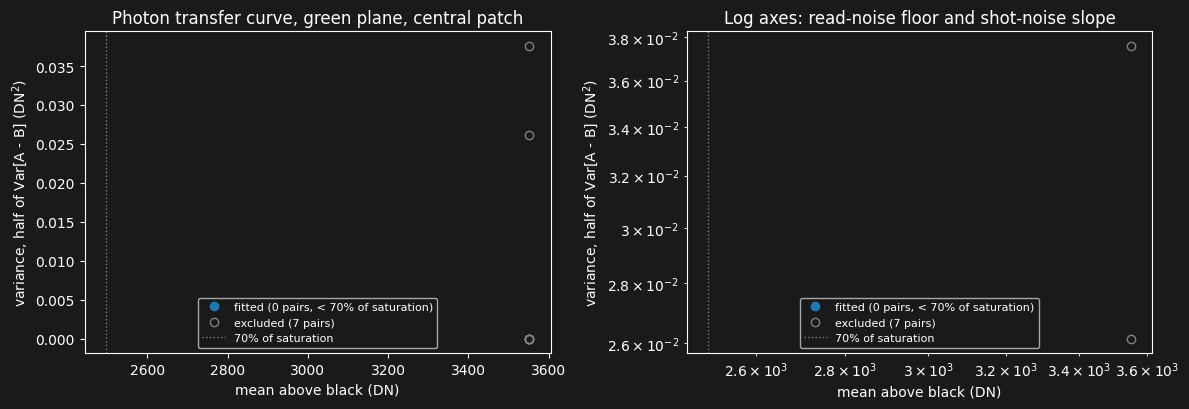

In [31]:
try:
    ptc_fit = fit_ptc(ptc_df.mean_DN, ptc_df.variance_DN2, full_scale=FULL_SCALE, frac=0.70)
except ValueError as err:
    ptc_fit = None
    print(f"! Fit not possible: {err}")

used = ((ptc_df.mean_DN > 0) & (ptc_df.mean_DN < 0.70 * FULL_SCALE)).to_numpy()
x, y = ptc_df.mean_DN.to_numpy(), ptc_df.variance_DN2.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, log in zip(axes, (False, True)):
    ax.plot(x[used], y[used], "o", ms=6, color="tab:blue",
            label=f"fitted ({used.sum()} pairs, < 70% of saturation)")
    ax.plot(x[~used], y[~used], "o", ms=6, mfc="none", color="gray",
            label=f"excluded ({(~used).sum()} pairs)")
    ax.axvline(0.70 * FULL_SCALE, ls=":", color="gray", lw=1, label="70% of saturation")

    if ptc_fit is not None:
        K, c, cov = ptc_fit["K"], ptc_fit["intercept"], ptc_fit["cov"]
        lo = max(x[x > 0].min() * 0.5, 1e-3) if log else 0
        xs = np.geomspace(lo, x.max() * 1.05, 200) if log else np.linspace(0, x.max() * 1.05, 200)
        line = K * xs + c
        X = np.c_[xs, np.ones_like(xs)]
        band = np.sqrt(np.einsum("ij,jk,ik->i", X, cov, X))   # 1-sigma on the fitted line
        ax.plot(xs, line, "-", lw=2, color="tab:green",
                label=f"fit: K = {K:.4f} DN/e$^-$, $\\sigma_r$ = {ptc_fit['read']:.2f} e$^-$")
        ax.fill_between(xs, line - band, line + band, color="tab:green", alpha=0.2,
                        label="fit $\\pm 1\\sigma$")
        if log and c > 0:
            ax.axhline(c, ls="--", lw=1.2, color="tab:orange",
                       label=f"read-noise floor $K^2\\sigma_r^2$ = {c:.2f} DN$^2$")

    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title("Log axes: read-noise floor and shot-noise slope")
    else:
        ax.set_title("Photon transfer curve, green plane, central patch")
    ax.set_xlabel("mean above black (DN)")
    ax.set_ylabel("variance, half of Var[A - B] (DN$^2$)")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig("hw3_item6_ptc.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
if ptc_fit is not None:
    K, sK = ptc_fit["K"], ptc_fit["sig_K"]
    R, sR = ptc_fit["read"], ptc_fit["sig_read"]
    c, sc = ptc_fit["intercept"], ptc_fit["sig_intercept"]
    print(f"Fit through {ptc_fit['used'].sum()} pairs below 70% of saturation "
          f"(weighted by 1/variance)")
    print(f"  slope     K       = {K:.4f} ± {sK:.4f} DN/e-   ({100 * sK / K:.1f}%)")
    print(f"  intercept K²σr²   = {c:.3f} ± {sc:.3f} DN²")
    print(f"  read noise σr     = {R:.2f} ± {sR:.2f} e-      ({100 * sR / R:.1f}%)"
          if np.isfinite(R) else "  read noise: intercept is not positive, so σr is undefined")
    print(f"  inverse gain 1/K  = {1 / K:.3f} e-/DN")

### Problem 7: Repeat the fit using the variance of a single frame at each level in place of the difference of pairs, and report both gains. The two disagree because one quantity present in the photographs is absent from the model. Name that quantity, and say which way it moves the gain and why.
_Deliverable: Both gains, their percentage difference, and a written explanation (2 to 3 sentences)._

In [33]:
single_var = []
for row in ptc_df.itertuples():
    fa, fb = row.frames.split(", ")
    a, black, _ = green_plane(WHITE_DIR / fa)
    b, _, _ = green_plane(WHITE_DIR / fb)
    # Variance of one frame on its own; averaging the two frames' single-frame
    # variances reduces scatter but keeps the fixed pattern in.
    single_var.append(0.5 * (np.var(center_patch(a), ddof=1) + np.var(center_patch(b), ddof=1)))

ptc_df["variance_single_DN2"] = single_var
ptc_df[["pair", "exposure", "mean_DN", "variance_DN2", "variance_single_DN2"]].round(3)

,pair,exposure,mean_DN,variance_DN2,variance_single_DN2
0,1,1/30 s,3551.460,0.038,219.251
1,2,1/15 s,3551.430,0.000,219.580
2,3,1/8 s,3551.402,0.026,220.021
3,4,1/4 s,3551.375,0.000,220.461
4,5,1/3 s,3552.129,0.000,214.014
5,6,1/2 s,3552.129,0.000,214.014
6,7,1 s,3552.129,0.000,214.014


In [34]:
def compare_fits(mean, var_pair, var_single, full_scale, label=""):
    fp = fit_ptc(mean, var_pair, full_scale)
    fs = fit_ptc(mean, var_single, full_scale)
    pct_diff = 100 * (fs["K"] - fp["K"]) / fp["K"]

    # The excess single-frame variance should grow as (PRNU * mean)^2 if it is
    # fixed-pattern gain variation: fit excess = p^2 * mean^2 + const.
    u = fp["used"]
    m = np.asarray(mean)[u]
    excess = np.asarray(var_single)[u] - np.asarray(var_pair)[u]
    coef, *_ = np.linalg.lstsq(np.c_[m**2, np.ones_like(m)], excess, rcond=None)
    prnu = np.sqrt(coef[0]) if coef[0] > 0 else np.nan

    print(f"{label}difference of pairs: K = {fp['K']:.4f} ± {fp['sig_K']:.4f} DN/e-")
    print(f"{label}single frame:        K = {fs['K']:.4f} ± {fs['sig_K']:.4f} DN/e-")
    print(f"{label}percentage difference (single vs. pair): {pct_diff:+.1f}%")
    print(f"{label}excess variance fits (p * mean)^2 with p = {100 * prnu:.2f}% "
          f"(fixed-pattern gain variation, PRNU)")
    return fp, fs, pct_diff, prnu


try:
    fit_pair, fit_single, pct_diff, prnu_est = compare_fits(
        ptc_df.mean_DN, ptc_df.variance_DN2, ptc_df.variance_single_DN2, FULL_SCALE)
except ValueError as err:
    fit_pair = fit_single = None
    print(f"! Fit not possible: {err}")

if fit_single is not None:
    x = ptc_df.mean_DN.to_numpy()
    u = fit_pair["used"]
    xs = np.linspace(0, x[u].max() * 1.05, 100)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(x[u], ptc_df.variance_DN2[u], "o", color="tab:blue", label="difference of pairs")
    ax.plot(x[u], ptc_df.variance_single_DN2[u], "s", color="tab:red", label="single frame")
    ax.plot(xs, fit_pair["K"] * xs + fit_pair["intercept"], "-", color="tab:blue",
            label=f"K = {fit_pair['K']:.4f} DN/e$^-$")
    ax.plot(xs, fit_single["K"] * xs + fit_single["intercept"], "-", color="tab:red",
            label=f"K = {fit_single['K']:.4f} DN/e$^-$ ({pct_diff:+.1f}%)")
    ax.set_xlabel("mean above black (DN)"); ax.set_ylabel("variance (DN$^2$)")
    ax.set_title("Single-frame variance includes the fixed pattern")
    ax.legend(fontsize=8.5)
    fig.tight_layout(); fig.savefig("hw3_item7_single_vs_pair.png", dpi=150); plt.show()

! Fit not possible: Only 0 points below 70% of saturation; need at least 4.


In [35]:
sim_single = [0.5 * (np.var(a, ddof=1) + np.var(b, ddof=1)) for a, b in sim_pairs]
_ = compare_fits(sim_stats[:, 0], sim_stats[:, 1], sim_single,
                 psu.WHITE_LEVEL - psu.BLACK_LEVEL, label="[simulator] ")
print(f"[simulator] true PRNU = {100 * SIM_PRNU:.2f}%")

[simulator] difference of pairs: K = 0.4233 ± 0.0011 DN/e-
[simulator] single frame:        K = 0.4833 ± 0.0177 DN/e-
[simulator] percentage difference (single vs. pair): +14.2%
[simulator] excess variance fits (p * mean)^2 with p = 1.18% (fixed-pattern gain variation, PRNU)
[simulator] true PRNU = 1.20%


Deliverable: Both gains, their percentage difference, and a written explanation (2 to 3 sentences).

### Problem 8: Report your full well capacity in electrons and your dynamic range in stops. More than one convention exists for the low end of the dynamic range, and the number you get depends on which you adopt, so state yours.
_Deliverable: Full well in electrons, dynamic range in stops, and the criterion you used._

In [36]:
K, sK = ptc_fit["K"], ptc_fit["sig_K"]
R, sR = ptc_fit["read"], ptc_fit["sig_read"]
c, sc = ptc_fit["intercept"], ptc_fit["sig_intercept"]

# --- Full well: the signal at which the raw values clip, in electrons --------
full_well = FULL_SCALE / K
sig_full_well = full_well * sK / K

# Cross-check: the variance turnover (EMVA 1288 "saturation capacity").
i_peak = int(np.argmax(ptc_df.variance_DN2))
peak_mean = ptc_df.mean_DN.iloc[i_peak]
peak_bracketed = 0 < i_peak < len(ptc_df) - 1

# --- Dynamic range under three low-end conventions --------------------------
def stops(ratio):
    return np.log2(ratio)

# 1. Read-noise floor: lowest usable signal = sigma_r electrons.
#    FW / sigma_r = (FULL_SCALE/K) / (sqrt(c)/K) = FULL_SCALE / sqrt(c), so only the
#    intercept's uncertainty enters.
dr_read = stops(FULL_SCALE / np.sqrt(c))
sig_dr_read = (sc / (2 * c)) / np.log(2)

# 2. EMVA 1288: signal where SNR = 1 counting its own shot noise,
#    mu / sqrt(mu + sigma_r^2) = 1  ->  mu_min = (1 + sqrt(1 + 4 sigma_r^2)) / 2
mu_min_emva = (1 + np.sqrt(1 + 4 * R**2)) / 2
dr_emva = stops(full_well / mu_min_emva)

# 3. A stricter photographic floor: signal where SNR = 10.
#    mu^2 = 100 (mu + sigma_r^2)  ->  mu = (100 + sqrt(100^2 + 400 sigma_r^2)) / 2
mu_min_snr10 = (100 + np.sqrt(100**2 + 400 * R**2)) / 2
dr_snr10 = stops(full_well / mu_min_snr10)

print(f"Full well (clip level)   {full_well:,.0f} ± {sig_full_well:,.0f} e-   "
      f"= ({FULL_SCALE:.0f} DN white minus black) / K")
if peak_bracketed:
    print(f"Variance turnover        {peak_mean / K:,.0f} e-   "
          f"(pair {ptc_df.pair.iloc[i_peak]}, cross-check)")
else:
    print(f"Variance turnover        not bracketed: the largest variance is at the "
          f"{'highest' if i_peak else 'lowest'} level, so no pair sits on the clipping knee")

dr_table = pd.DataFrame({
    "low-end criterion": ["read-noise floor: signal = sigma_r (used)",
                          "EMVA 1288: SNR = 1 including shot noise",
                          "photographic: SNR = 10"],
    "lowest signal (e-)": [R, mu_min_emva, mu_min_snr10],
    "dynamic range (stops)": [dr_read, dr_emva, dr_snr10],
})
print(f"\nDynamic range (adopted, read-noise floor): {dr_read:.2f} ± {sig_dr_read:.2f} stops")
dr_table.round(2).style.hide(axis="index")

TypeError: 'NoneType' object is not subscriptable

Deliverable: Full well in electrons, dynamic range in stops, and the criterion you used.

## Part 3: Signal to Noise
### Problem 9: Plot your measured signal-to-noise ratio against signal in electrons on logarithmic axes, draw the curve predicted by your fitted gain and read noise over it, and mark the knee.
_Deliverable: The figure, the knee in electrons, and one sentence on whether your captures actually reach into both regimes._

In [37]:
K, R = ptc_fit["K"], ptc_fit["read"]
knee_e = R**2                                   # shot variance = read variance here

snr_df = ptc_df[["pair", "exposure", "mean_DN", "variance_DN2"]].copy()
snr_df = snr_df[(snr_df.mean_DN > 0) & (snr_df.variance_DN2 > 0)]
snr_df["signal_e"] = snr_df.mean_DN / K
snr_df["snr_measured"] = snr_df.mean_DN / np.sqrt(snr_df.variance_DN2)
snr_df["snr_model"] = snr_df.signal_e / np.sqrt(snr_df.signal_e + R**2)
snr_df["in_fit"] = snr_df.mean_DN < 0.70 * FULL_SCALE
snr_df["regime"] = np.where(snr_df.signal_e < knee_e, "read-noise", "shot-noise")

mu = np.geomspace(min(snr_df.signal_e.min(), knee_e) / 3, snr_df.signal_e.max() * 1.5, 300)
mu_low = mu[mu < 10 * knee_e]                   # draw the read-noise asymptote only near the knee

fig, ax = plt.subplots(figsize=(7.5, 4.6))
fit_pts, out_pts = snr_df[snr_df.in_fit], snr_df[~snr_df.in_fit]
ax.loglog(fit_pts.signal_e, fit_pts.snr_measured, "o", ms=6, color="tab:blue",
          label="measured (pairs used in the fit)")
if len(out_pts):
    ax.loglog(out_pts.signal_e, out_pts.snr_measured, "o", ms=6, mfc="none", color="gray",
              label="measured (above 70% of saturation)")
ax.loglog(mu, mu / np.sqrt(mu + R**2), "-", lw=2, color="tab:green",
          label=f"model: K = {K:.4f} DN/e$^-$, $\\sigma_r$ = {R:.2f} e$^-$")
ax.loglog(mu, np.sqrt(mu), "--", lw=1.2, color="tab:orange",
          label=r"shot-noise limit $\sqrt{\mu}$ (slope 1/2)")
ax.loglog(mu_low, mu_low / R, ":", lw=1.5, color="tab:red",
          label=r"read-noise limit $\mu/\sigma_r$ (slope 1)")
ax.axvline(knee_e, color="k", lw=1)
ax.annotate(f"knee\n{knee_e:.1f} e$^-$", xy=(knee_e, knee_e / np.sqrt(2 * knee_e)),
            xytext=(knee_e * 2.2, knee_e / np.sqrt(2 * knee_e) / 2.5), fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("signal (electrons)")
ax.set_ylabel("SNR")
ax.set_title("Signal-to-noise ratio, measured against the fitted model")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("hw3_item9_snr.png", dpi=150, bbox_inches="tight")
plt.show()

rel_err = (snr_df.snr_measured - snr_df.snr_model) / snr_df.snr_model
counts = snr_df.regime.value_counts()
print(f"Knee: mu = sigma_r^2 = {knee_e:.1f} e-  ({knee_e * K:.2f} DN above black)")
print(f"Signal range measured: {snr_df.signal_e.min():.1f} to {snr_df.signal_e.max():,.0f} e-")
print(f"Pairs below the knee (read-noise regime): {counts.get('read-noise', 0)}; "
      f"above (shot-noise regime): {counts.get('shot-noise', 0)}")
print(f"Median |measured - model| / model: {100 * np.median(np.abs(rel_err[snr_df.in_fit])):.1f}% "
      f"over the fitted pairs")

TypeError: 'NoneType' object is not subscriptable

Deliverable: The figure, the knee in electrons, and one sentence on whether your captures actually reach into both regimes.

### Problem 10: Check whether your DNG carries a NoiseProfile tag, which is the manufacturer's own noise model. If it is present, convert it into a gain and a read noise that can be compared against yours; the tag is written in units of normalized signal, so the conversion is a matter of carrying the white level minus the black level through the model.
_Deliverable: The vendor figures beside your own, or a statement that the tag is absent._

In [38]:
NOISE_PROFILE_TAG = 51041          # DNG NoiseProfile: (S, O) per color plane

def read_noise_profile(path):
    """The NoiseProfile tag as an (n_planes, 2) array of (S, O), or None if absent.
    Checks IFD0 and its SubIFDs, since the raw image usually sits in a SubIFD."""
    with tifffile.TiffFile(path) as t:
        first = t.pages[0]
        pages = [first] + (list(first.pages) if first.pages else [])
        for p in pages:
            tag = p.tags.get(NOISE_PROFILE_TAG)
            if tag is not None:
                return np.asarray(tag.value, dtype=float).ravel().reshape(-1, 2)
    return None


profiles = {f.name: read_noise_profile(f) for f in dng_files(WHITE_DIR)}
present = {k: v for k, v in profiles.items() if v is not None}
print(f"NoiseProfile present in {len(present)} of {len(profiles)} flat-field files")

if present:
    distinct = {tuple(v.ravel()) for v in present.values()}
    if len(distinct) > 1:
        print(f"! {len(distinct)} different profiles across files:")
        for k, v in present.items():
            print(f"    {k}: {v.ravel()}")
    profile = next(iter(present.values()))
    print(f"Profile (S, O) per plane, normalized units:\n{profile}")

NoiseProfile present in 14 of 14 flat-field files
Profile (S, O) per plane, normalized units:
[[8.85807e-05 9.87416e-07]]


In [39]:
if present:
    K, sK = ptc_fit["K"], ptc_fit["sig_K"]
    R, sR = ptc_fit["read"], ptc_fit["sig_read"]

    # Normalized signal x = (D - B) / (W - B), so Var(x) = S x + O becomes
    #   Var(D) = (W - B) S (D - B) + (W - B)^2 O
    # Matching K (D - B) + K^2 sigma_r^2 term by term:
    #   K_vendor = S (W - B),   sigma_r,vendor = sqrt(O) (W - B) / K_vendor = sqrt(O) / S
    plane = 1 if len(profile) == 3 else 0      # green plane if given per color, else the only one
    S, O = profile[plane]
    K_vendor = S * FULL_SCALE
    R_vendor = np.sqrt(O) / S if O > 0 else np.nan

    vendor_df = pd.DataFrame({
        "quantity": ["conversion gain K (DN/e-)", "read noise (e-)"],
        "vendor (NoiseProfile)": [K_vendor, R_vendor],
        "mine (photon transfer)": [K, R],
        "my fit uncertainty": [sK, sR],
        "mine vs. vendor (%)": [100 * (K - K_vendor) / K_vendor,
                                100 * (R - R_vendor) / R_vendor],
    })
    print(f"Using plane {plane} of {len(profile)}: S = {S:.4e}, O = {O:.4e}; "
          f"white - black = {FULL_SCALE:.0f} DN")
    display(vendor_df.round(4).style.hide(axis="index"))
else:
    print("The NoiseProfile tag (51041) is absent from these DNGs, so there are no vendor "
          "figures to compare against.")

TypeError: 'NoneType' object is not subscriptable

## Part 4: Dark Current
### Problem 11: Fit the dark current from the capped frames you took in item 3 by plotting their mean against exposure time and converting the slope to electrons per second with your gain. Dark current roughly doubles for every 6 to 8 degrees Celsius, so note whether the phone was warm. If your longest available exposure is only a fraction of a second, the result may be indistinguishable from zero, and in that case an upper bound with an argument behind it is the correct answer.
_Deliverable: The figure, and the dark current in electrons per second with an uncertainty, or a defended upper bound._

In [42]:
DARK_CHANNEL = "G1"        # same Bayer site as green_plane(), so the gain K applies directly

def fit_dark(df):
    t = df.exposure_s.to_numpy()
    y = (df.mean_DN - df.black_DN).to_numpy()
    (slope, icpt), cov = np.polyfit(t, y, 1, cov=True)    # cov scaled by the actual scatter
    return slope, icpt, cov

K, sK = ptc_fit["K"], ptc_fit["sig_K"]
rows = []
for ch, grp in dark_ch.groupby("channel", sort=False):
    slope, icpt, cov = fit_dark(grp)
    s_slope = np.sqrt(cov[0, 0])
    rows.append({"channel": ch, "slope_DN_per_s": slope, "sigma_DN_per_s": s_slope,
                 "intercept_DN": icpt, "significance": slope / s_slope})
dark_fits = pd.DataFrame(rows)

g = dark_ch[dark_ch.channel == DARK_CHANNEL]
slope, icpt, cov = fit_dark(g)
s_slope = np.sqrt(cov[0, 0])
dc = slope / K                                                   # e-/s
s_dc = abs(dc) * np.sqrt((s_slope / slope) ** 2 + (sK / K) ** 2) if slope else s_slope / K
t_max = g.exposure_s.max()

# --- figure ------------------------------------------------------------------
ts = np.linspace(0, t_max * 1.05, 100)
X = np.c_[ts, np.ones_like(ts)]
band = np.sqrt(np.einsum("ij,jk,ik->i", X, cov, X))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for ch, grp in dark_ch.groupby("channel", sort=False):
    if ch != DARK_CHANNEL:
        ax.plot(grp.exposure_s, grp.mean_DN - grp.black_DN, ".", alpha=0.35, label=f"{ch} frames")
ax.plot(g.exposure_s, g.mean_DN - g.black_DN, "o", ms=7, color="tab:purple",
        label=f"{DARK_CHANNEL} frames (fitted)")
ax.plot(ts, slope * ts + icpt, "-", lw=2, color="k",
        label=f"fit: {slope:+.3f} ± {s_slope:.3f} DN/s")
ax.fill_between(ts, slope * ts + icpt - band, slope * ts + icpt + band,
                color="k", alpha=0.12, label="fit ± 1σ")
ax.axhline(0, color="gray", lw=0.8, ls=":")
ax.set_xlabel("exposure time (s)")
ax.set_ylabel("dark-frame mean minus file black level (DN)")
sec = ax.secondary_yaxis("right", functions=(lambda d: d / K, lambda e: e * K))
sec.set_ylabel("electrons")
ax.set_title("Dark signal against exposure time (lens covered)")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig("hw3_item11_dark_current.png", dpi=150, bbox_inches="tight")
plt.show()

# --- result ------------------------------------------------------------------
print(dark_fits.round(4).to_string(index=False))
print(f"\n{DARK_CHANNEL}: slope {slope:+.4f} ± {s_slope:.4f} DN/s over 0 to {t_max:g} s, "
      f"{len(g)} frames; K = {K:.4f} DN/e-")
if abs(slope) > 2 * s_slope:
    print(f"Dark current = {dc:.2f} ± {s_dc:.2f} e-/s  (slope is {slope / s_slope:.1f} sigma from zero)")
else:
    ub = (max(slope, 0) + 1.645 * s_slope) / K          # one-sided 95% upper limit
    print(f"Slope is consistent with zero ({slope / s_slope:+.1f} sigma).")
    print(f"95% upper bound: dark current < {ub:.2f} e-/s")
    print(f"  -> at the longest exposure ({t_max:g} s) that is < {ub * t_max:.2f} e- of dark signal, "
          f"against a read noise of {ptc_fit['read']:.2f} e-")

TypeError: 'NoneType' object is not subscriptable

## Part 5: Linear Light
### Problem 12: Construct a checkerboard of pure black and pure white pixels, exactly half of each, and compute its mean twice: once by averaging the sRGB-encoded values directly, and once by linearizing, averaging, and re-encoding.
_Deliverable: Both values, and one sentence identifying which of them is the brightness a camera pointed at that checkerboard would have recorded._

In [43]:
def srgb_decode(v):
    """Piecewise sRGB transfer function, encoded [0, 1] -> linear [0, 1]."""
    v = np.clip(v, 0, 1)
    return np.where(v <= 0.04045, v / 12.92, ((v + 0.055) / 1.055) ** 2.4)

# Round-trip check that the two curves are inverses
_t = np.linspace(0, 1, 1001)
assert np.allclose(srgb_decode(srgb_encode(_t)), _t, atol=1e-12)

# Checkerboard of pure black and pure white, exactly half of each (sRGB-encoded values)
N = 256
yy, xx = np.indices((N, N))
board = ((xx + yy) % 2).astype(float)          # 0 = black, 1 = white
assert board.mean() == 0.5 and board.size % 2 == 0

mean_encoded = board.mean()                                   # average the encoded values
mean_linear = srgb_encode(srgb_decode(board).mean())          # linearize, average, re-encode

# For comparison: the same calculation with a bare 2.2 power law instead of the sRGB curve
mean_gamma22 = srgb_decode(board).mean() ** (1 / 2.2)

try:                                                          # optional cross-check
    import colour
    check = colour.cctf_encoding(colour.cctf_decoding(board, "sRGB").mean(), "sRGB")
    print(f"colour-science cross-check of the linear-light mean: {check:.4f}")
except ImportError:
    pass

checker_df = pd.DataFrame({
    "method": ["average the sRGB-encoded values",
               "linearize, average, re-encode (sRGB curve)",
               "linearize, average, re-encode (bare 2.2 power, for comparison)"],
    "encoded value [0, 1]": [mean_encoded, mean_linear, mean_gamma22],
    "8-bit level": [255 * mean_encoded, 255 * mean_linear, 255 * mean_gamma22],
    "linear light it stands for": [srgb_decode(mean_encoded), srgb_decode(mean_linear),
                                   srgb_decode(mean_gamma22)],
})
checker_df.round(4).style.hide(axis="index")

method,"encoded value [0, 1]",8-bit level,linear light it stands for
average the sRGB-encoded values,0.500000,127.500000,0.21404114048223255
"linearize, average, re-encode (sRGB curve)",0.7353569830524495,187.516000,0.5
"linearize, average, re-encode (bare 2.2 power, for comparison)",0.729740,186.083700,0.491514193429914


### Problem 13: Do the same thing to real data. Take one of your checkerboard calibration captures from Exercise 1, extract a green plane, encode it to sRGB, and then reduce it by a factor of eight two ways: by averaging the encoded values, and by averaging in linear light and encoding afterward.
_Deliverable: The two reduced images and their difference, the mean absolute difference in 8-bit levels, and one sentence on where in the image the error concentrates._

In [44]:
CHECKER_PATH = CAPTURE_ROOT / "IMG_0322.DNG"
REDUCE = 8

def linear_green(path):
    """Green plane as linear light in [0, 1] of the raw range.
    Handles both a Bayer DNG (one green site of the mosaic) and a demosaiced
    LinearRaw DNG such as Apple ProRAW (the G channel of the RGB stack)."""
    with rawpy.imread(str(path)) as r:
        is_bayer = r.raw_pattern is not None
        if not is_bayer:                                # LinearRaw: already RGB, already linearized
            desc = r.color_desc.decode()
            gi = desc.index("G")
            g = r.raw_image_visible[..., gi].astype(np.float64)   # copy before the file closes
            black = float(r.black_level_per_channel[gi])
            white = float(r.white_level)
            kind = f"LinearRaw (demosaiced) {r.raw_image_visible.shape[:2]}, channel {gi}"
    if is_bayer:
        g, black, white = green_plane(path)
        kind = "Bayer mosaic, one green site"
    return np.clip((g - black) / (white - black), 0, 1), kind, black, white


def block_mean(x, factor=REDUCE):
    h, w = (s // factor * factor for s in x.shape)
    return x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))


lin, kind, blk, wht = linear_green(CHECKER_PATH)
enc = srgb_encode(lin)                                  # full-resolution sRGB-encoded green plane

reduced_encoded = block_mean(enc)                       # 1. average the encoded values
reduced_linear = srgb_encode(block_mean(lin))           # 2. average in linear light, then encode
diff_8bit = 255 * (reduced_linear - reduced_encoded)    # positive where linear averaging is brighter

mad = np.mean(np.abs(diff_8bit))
print(f"{CHECKER_PATH.name}: {kind}; black {blk:.0f}, white {wht:.0f}")
print(f"Full resolution {lin.shape}, reduced by {REDUCE} to {reduced_linear.shape}")
print(f"Mean absolute difference: {mad:.2f} 8-bit levels (max {np.abs(diff_8bit).max():.1f})")

IMG_0322.DNG: LinearRaw (demosaiced) (3024, 4032), channel 1; black 0, white 65535
Full resolution (3024, 4032), reduced by 8 to (378, 504)
Mean absolute difference: 0.20 8-bit levels (max 16.8)


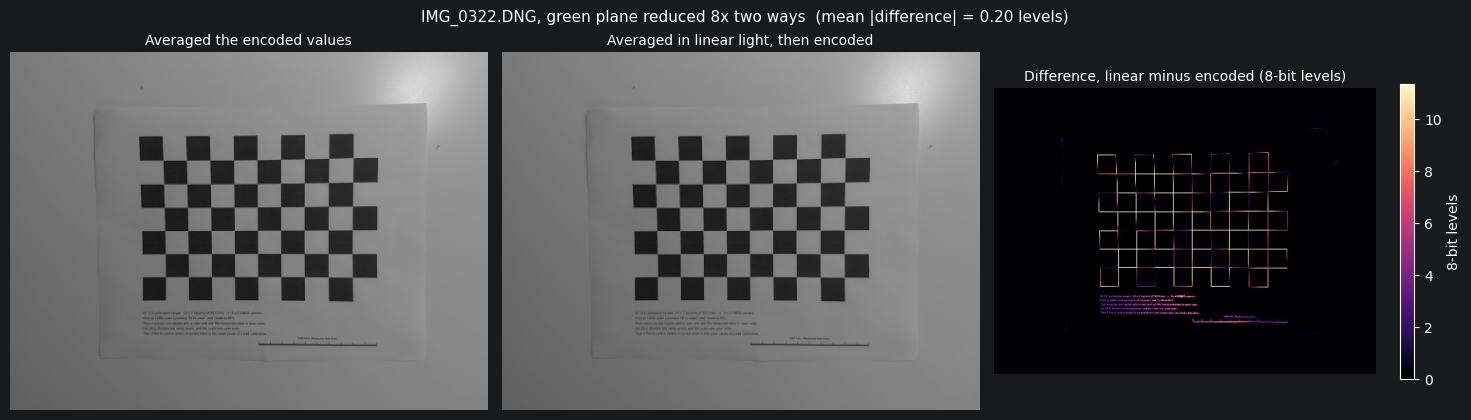

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, img, title in ((axes[0], reduced_encoded, "Averaged the encoded values"),
                       (axes[1], reduced_linear, "Averaged in linear light, then encoded")):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10); ax.axis("off")
im = axes[2].imshow(diff_8bit, cmap="magma", vmin=0, vmax=np.percentile(diff_8bit, 99.5))
axes[2].set_title("Difference, linear minus encoded (8-bit levels)", fontsize=10); axes[2].axis("off")
fig.colorbar(im, ax=axes[2], shrink=0.8, label="8-bit levels")
fig.suptitle(f"{CHECKER_PATH.name}, green plane reduced {REDUCE}x two ways  "
             f"(mean |difference| = {mad:.2f} levels)", fontsize=11)
fig.tight_layout()
fig.savefig("hw3_item13_reduction.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
# Sort the reduced blocks by how much the light varies inside them.
local_var = block_mean(lin**2) - block_mean(lin)**2          # within-block variance, linear
local_sd = np.sqrt(np.clip(local_var, 0, None))
edges = local_sd >= np.percentile(local_sd, 90)
flat = local_sd <= np.percentile(local_sd, 50)
print(f"Blocks with the most variation inside them (top 10%): mean |diff| = "
      f"{np.abs(diff_8bit[edges]).mean():.2f} levels")
print(f"Uniform blocks (bottom 50%):                          mean |diff| = "
      f"{np.abs(diff_8bit[flat]).mean():.2f} levels")
print(f"Share of the total absolute error in the top 10% of blocks: "
      f"{100 * np.abs(diff_8bit[edges]).sum() / np.abs(diff_8bit).sum():.0f}%")
print(f"Fraction of blocks where linear averaging is brighter: {100 * (diff_8bit > 0).mean():.1f}%")

Blocks with the most variation inside them (top 10%): mean |diff| = 1.89 levels
Uniform blocks (bottom 50%):                          mean |diff| = 0.01 levels
Share of the total absolute error in the top 10% of blocks: 95%
Fraction of blocks where linear averaging is brighter: 100.0%


The two reductions differ by a mean of 0.20 8-bit levels (up to 16.8), and the error concentrates almost entirely on the edges of the squares and the printed text: blocks that straddle a black-white boundary average 1.9 levels darker when the encoded values are averaged, which carries 95% of the total error, while uniform regions of paper or square interiors differ by only 0.01 levels.

## Part 6: Reflections
### Problem 14: What did you learn from this assignment?
_Deliverable: A brief written response._

### Problem 15: What questions, if any, do you have for me after completing this assignment?
_Deliverable: A brief written response._